# Deep stochastic control (Han & E) vs closed-form deltas: European and American digitals in the Bachelier model

Companion to `han_e_bartlett_sabr.ipynb`. There, in an incomplete market, the Han–E stacked-policy network found Bartlett's
delta rather than the Black–Scholes delta — a test of the *theory* (quadratic hedging = variance-optimal projection). Here the
market is complete, the variance-optimal hedge is the replicating delta and it is available in closed form, so what is being
tested is the *numerics*: whether one feed-forward subnetwork per time step, stacked through the wealth dynamics and trained
by Monte-Carlo SGD on the mean-square hedging error, recovers controls that are

* driven by a discontinuous payoff and spike like $1/(\sigma\sqrt{\tau})$ into expiry (European digital), and
* path-dependent, with an augmented state and a hard switch to zero after the knock-in (American digital = one-touch).

Everything is in rates units (Bachelier/NBS is the normal-vol convention): $S$ is a rate, $S_0=3.00\%$, $\sigma_N=80$bp/yr,
$T=1$y, strike/barrier $K=3.60\%$ (0.75 $\sigma\sqrt T$ out of the money) for both payoffs, 100 rebalancing steps.

References — Han & E, *Deep Learning Approximation for Stochastic Control Problems*, arXiv:1611.07422 (2016) ·
Föllmer & Schweizer, *Hedging by sequential regression* (1988) · Broadie, Glasserman & Kou, *A continuity correction for
discrete barrier options* (1997).

## 1. Model, payoffs, closed forms — and what the *discrete-time* optimum is

Bachelier model, zero rates, pricing measure: $dS_t=\sigma\,dW_t$, so on the hedging grid $S_{k+1}=S_k+\sigma\sqrt{\Delta t}\,Z_k$
with i.i.d. standard normal $Z_k$.

**European digital** $H=\mathbf 1_{\{S_T>K\}}$: with $d=(S-K)/(\sigma\sqrt\tau)$,
$$v(t,S)=\Phi(d),\qquad \partial_S v=\frac{\phi(d)}{\sigma\sqrt\tau}.$$

**American digital.** With zero rates a holder-exercisable digital is exercised at the first touch of $K$ (1 is the most it can
ever pay), so it is the one-touch $H=\mathbf 1_{\{\max_{t\le T}S_t\ge K\}}$, pay-at-hit and pay-at-expiry being the same. By the
reflection principle, before the touch ($S<K$)
$$u(t,S)=2\,\Phi(d),\qquad \partial_S u=\frac{2\,\phi(d)}{\sigma\sqrt\tau},$$
and $u\equiv1$, $\partial_S u\equiv 0$ after it. So on untouched states the American digital's delta is exactly **twice** the
European digital's — a parameter-free prediction the two learned policies can be checked against.

**What the network is actually asked to find.** Quadratic hedging on the grid under a martingale $S$ decomposes over the steps,
$$E\Big[\big(H-w-\textstyle\sum_k\theta_k\Delta S_k\big)^2\Big]=(V_0-w)^2+\sum_k E\big[(V_{k+1}-V_k-\theta_k\Delta S_k)^2\big],
\qquad V_k=E[H\mid\mathcal F_k],$$
so the optimum is $w^*=V_0$ and the one-step regression coefficient $\theta_k^*=\mathrm{Cov}(V_{k+1},\Delta S_k\mid\mathcal F_k)/\mathrm{Var}(\Delta S_k\mid\mathcal F_k)$.

* *European payoff.* With Gaussian increments Stein's lemma gives $\theta^*_k=E[\partial_S v(t_{k+1},S_{k+1})\mid S_k]$, and
  $\partial_S v$ solves the same backward heat equation as $v$, so $\theta^*_k=\partial_S v(t_k,S_k)$ **exactly, on any grid**.
  The discrete-time quadratic-hedging optimum of the digital *is* the closed-form Bachelier delta — unlike SABR, where the
  benchmark held only up to the $\hat\Sigma$ approximation and $O(\Delta t)$. Any discrepancy below is the method's.
* *One-touch.* The barrier is monitored continuously: crossings between grid points are sampled with the Brownian-bridge
  probability $p_k=\exp\!\big(-2(K-S_k)(K-S_{k+1})/(\sigma^2\Delta t)\big)$, so the claim is the genuine one-touch and $2\Phi(d)$
  prices it exactly. But now $E[V_{k+1}\mid S_k,S_{k+1}]=p_k+(1-p_k)\,u(t_{k+1},S_{k+1})$ depends on $S_k$ through $p_k$, and the
  Stein argument picks up an extra term:
  $$\theta^*_k=\partial_S u(t_k,S_k)-E\big[\partial_{S_k}p_k\,(1-u(t_{k+1},S_{k+1}))\mathbf 1_{\{S_{k+1}<K\}}\mid S_k\big]\;\le\;\partial_S u(t_k,S_k).$$
  The correction lives in a layer $K-S_k\lesssim\sigma\sqrt{\Delta t}$ below the barrier and is not small there: at the barrier
  itself the touch within the next step is certain whatever $\Delta S_k$ is, so $V_{k+1}\approx1$, the covariance vanishes and
  $\theta^*_k\to0$, while $\partial_S u$ stays at $2\phi(0)/(\sigma\sqrt\tau)$. We therefore compute $\theta^*_k$ by quadrature as
  the exact discrete-grid benchmark next to the closed form; the two coincide outside the layer, and the layer shrinks like
  $\sqrt{\Delta t}$.

In [1]:
import math, time
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ON_GPU = device.type == 'cuda'
if ON_GPU: torch.cuda.manual_seed_all(0)
print(f'device: {device}' + (f'  ({torch.cuda.get_device_name(0)})' if ON_GPU else '   <- no GPU found: reduced batch / iterations'))
T64 = dict(dtype=torch.float64, device=device)

# Bachelier (normal) model in rate units: S is a rate in decimals, SIGMA a normal vol per sqrt(year)
S0, SIGMA, T, K = 0.0300, 0.0080, 1.0, 0.0360          # 3.00 %, 80 bp/yr, 1 y, strike & barrier 3.60 %  (0.75 sigma sqrt(T) out of the money)
N_STEPS = 100; dt = T/N_STEPS
BP   = 1e-4                                            # hedge ratios are reported per basis point of the rate
UNIT = 1.0/(SIGMA*math.sqrt(T))                        # ... and learned in units of 1/(sigma sqrt T): a fixed choice of units (S measured in sigma-sqrt(T) moves)

# Han-E training budget
BATCH   = 8192  if ON_GPU else 2048
N_ITERS = 8000  if ON_GPU else 3000       # the one-touch keeps improving with samples: its hardest states (just below the barrier, late) are the rarest
N_TEST  = 2**17 if ON_GPU else 2**15
WIDTH, LR = 32, 2e-3
TIME_SCALED_OUTPUT = False     # True multiplies the control by sqrt(T/tau_k), i.e. tells the network how a digital's delta grows into expiry. Off: it has to find that itself.

COL   = dict(learned='#2a78d6', cf='#eb6834', exact='#1baf7a', ref='#333333')
LABEL = dict(learned='learned (Han–E)', cf='closed-form delta', exact='exact discrete-grid optimum (quadrature)')

device: cpu   <- no GPU found: reduced batch / iterations


European digital, steps k < N-1:  max relative |discrete-grid optimum - closed-form delta| = 1.8e-13


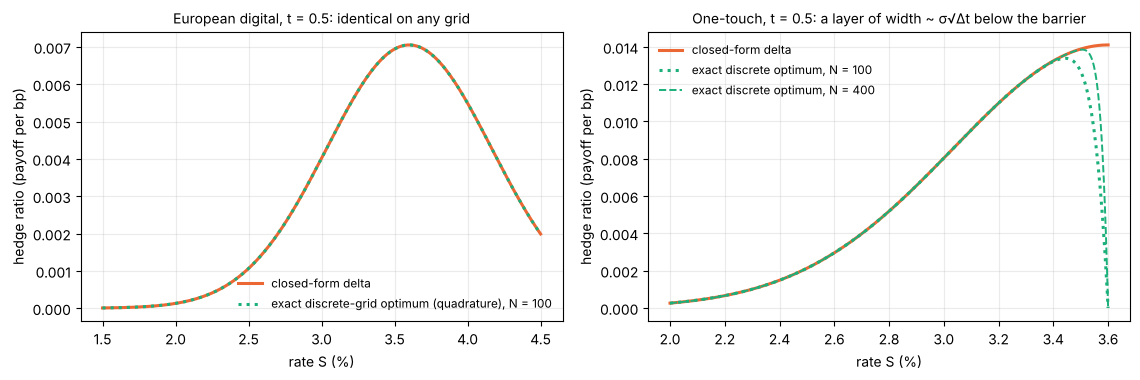

In [2]:
SQRT2, SQRT2PI = math.sqrt(2.0), math.sqrt(2*math.pi)
Phi = lambda x: 0.5*(1.0 + torch.erf(x/SQRT2))
phi = lambda x: torch.exp(-0.5*x*x)/SQRT2PI
TAU   = T - dt*torch.arange(N_STEPS, **T64)                       # time to maturity at each decision time t_k
tau_k = lambda k: torch.tensor(T - k*dt, **T64)

def digital_cf(S, tau):
    '''European (cash-or-nothing) digital call, Bachelier, zero rates:  price Phi(d),  delta phi(d)/(sigma sqrt(tau)).'''
    v = SIGMA*torch.sqrt(tau); d = (S - K)/v
    return Phi(d), phi(d)/v

def one_touch_cf(S, tau, touched):
    '''American digital = up-and-in one-touch paying 1 at the first touch of K.  Reflection principle:
       price 2 Phi(d), delta 2 phi(d)/(sigma sqrt(tau)) for S < K before the touch;  1 and 0 after it.'''
    v = SIGMA*torch.sqrt(tau); d = ((S - K)/v).clamp(max=0.0); hit = touched > 0.5
    return torch.where(hit, torch.ones_like(d), 2*Phi(d)), torch.where(hit, torch.zeros_like(d), 2*phi(d)/v)

def simulate(n, antithetic=True):
    '''Bachelier paths on the hedging grid (exact Gaussian steps) plus the continuously-monitored touch indicator
       1{max_{s<=t} S_s >= K}: crossings between grid points are sampled with the Brownian-bridge probability.'''
    m = n//2 if antithetic else n
    Z = torch.randn(m, N_STEPS, **T64)
    if antithetic: Z = torch.cat([Z, -Z], 0)
    S = torch.empty(Z.shape[0], N_STEPS + 1, **T64); S[:, 0] = S0
    S[:, 1:] = S0 + (SIGMA*math.sqrt(dt)*Z).cumsum(1)
    p_cross = torch.exp(-2*(K - S[:, :-1]).clamp(min=0)*(K - S[:, 1:]).clamp(min=0)/(SIGMA**2*dt))   # = 1 if an endpoint is at/above K
    crossed = (S[:, 1:] >= K) | (torch.rand(Z.shape[0], N_STEPS, **T64) < p_cross)
    touched = torch.zeros_like(S); touched[:, 1:] = torch.cummax(crossed.double(), 1).values
    return S, touched

pay_digital = lambda S, touched: (S[:, -1] > K).double()
pay_touch   = lambda S, touched: touched[:, -1]

# exact discrete-grid optimum  theta*_k(S) = Cov(V_{k+1}, dS_k | S_k = S) / Var(dS_k)  by quadrature over the Gaussian step
ZQ = torch.linspace(-8.0, 8.0, 8001, **T64); WQ = phi(ZQ)*(ZQ[1] - ZQ[0])

def discrete_optimum(k, S, kind, n_steps=N_STEPS, z=ZQ, w=WQ):
    '''For untouched states S at step k:  E[ g(S_{k+1}) Z ] / (sigma sqrt(h)),  g(S') = E[V_{k+1} | S_k = S, S_{k+1} = S'].'''
    h = T/n_steps; sd = SIGMA*math.sqrt(h); tau_next = T - (k + 1)*h
    Sn = S[:, None] + sd*z[None, :]
    if kind == 'digital':
        g = Phi((Sn - K)/(SIGMA*math.sqrt(tau_next))) if tau_next > 1e-12 else (Sn > K).double()
    else:
        u_next = 2*Phi(((Sn - K)/(SIGMA*math.sqrt(tau_next))).clamp(max=0)) if tau_next > 1e-12 else torch.zeros_like(Sn)
        p = torch.exp(-2*(K - S[:, None]).clamp(min=0)*(K - Sn).clamp(min=0)/(SIGMA**2*h))         # Brownian-bridge crossing probability
        g = torch.where(Sn >= K, torch.ones_like(Sn), p + (1 - p)*u_next)
    return (g*z*w).sum(1)/sd

# (i) European digital: the discrete-grid optimum is the closed-form delta (Stein's lemma + heat equation)
Sg = torch.linspace(0.015, 0.045, 301, **T64)
rel = max(((discrete_optimum(k, Sg, 'digital') - digital_cf(Sg, tau_k(k))[1]).abs().max()/digital_cf(Sg, tau_k(k))[1].max()).item()
          for k in (0, 10, 50, 90, 98))
print(f'European digital, steps k < N-1:  max relative |discrete-grid optimum - closed-form delta| = {rel:.1e}')

# (ii) one-touch: closed form vs discrete-grid optimum at t = 0.5 for N = 100 and N = 400 -- the barrier layer
Su = torch.linspace(0.020, K, 400, **T64); t_half = tau_k(50); zero = torch.zeros_like(Su)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax[0].plot(Sg.cpu()*100, digital_cf(Sg, t_half)[1].cpu()*BP, color=COL['cf'], lw=2.2, label=LABEL['cf'])
ax[0].plot(Sg.cpu()*100, discrete_optimum(50, Sg, 'digital').cpu()*BP, ':', color=COL['exact'], lw=2.2, label=LABEL['exact'] + ', N = 100')
ax[0].set_title('European digital, t = 0.5: identical on any grid', fontsize=10)
ax[1].plot(Su.cpu()*100, one_touch_cf(Su, t_half, zero)[1].cpu()*BP, color=COL['cf'], lw=2.2, label=LABEL['cf'])
ax[1].plot(Su.cpu()*100, discrete_optimum(50, Su, 'touch').cpu()*BP, ':', color=COL['exact'], lw=2.2, label='exact discrete optimum, N = 100')
ax[1].plot(Su.cpu()*100, discrete_optimum(200, Su, 'touch', n_steps=400).cpu()*BP, '--', color=COL['exact'], lw=1.4, label='exact discrete optimum, N = 400')
ax[1].set_title('One-touch, t = 0.5: a layer of width ~ σ√Δt below the barrier', fontsize=10)
for a in ax: a.set_xlabel('rate S (%)'); a.set_ylabel('hedge ratio (payoff per bp)'); a.legend(frameon=False, fontsize=8.5); a.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 2. The Han–E control problem

As in the SABR notebook: state $s_k=(S_k,\;\mathbf 1_{\{M_k\ge K\}},\;V_k)$ with $M_k$ the running maximum (the touch indicator is
the augmented state the one-touch needs; the digital's policy sees $S_k$ only), noise $\xi_{k+1}=Z_k$ plus the bridge draw,
control $a_k=\pi_k(s_k)$ = units of the rate held over $[t_k,t_{k+1})$, dynamics $V_{k+1}=V_k+a_k\Delta S_k$, terminal cost
$(H-w-V_N)^2$ with the initial capital $w$ trainable. One subnetwork per step (input → 2 hidden layers of 32 → output), a single
trainable number at $k=0$ where the state is deterministic, Adam on fresh antithetic Monte-Carlo noise every iteration.

Subnetwork inputs are the state in natural coordinates, $(S_k-K)/(\sigma\sqrt{T-t_k})$ and the touch indicator, and the control
is learned in units of $1/(\sigma\sqrt T)$ — both fixed rescalings. What the network is *not* told is how the control should
scale with time to maturity: `TIME_SCALED_OUTPUT=False` leaves the $1/\sqrt{\tau}$ growth of the digital's delta (a factor 10
between $t=0$ and the last step) for the optimisation to discover. The policy after the touch is likewise left to the network:
nothing hard-codes "the claim is settled, stop hedging".

In [3]:
class SubNet(nn.Module):
    '''Han-E subnetwork:  state -> [Linear -> activation] x 2 -> Linear -> control.'''
    def __init__(self, d_in, width=WIDTH):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, width), nn.SiLU(), nn.Linear(width, width), nn.SiLU(), nn.Linear(width, 1))
        nn.init.constant_(self.net[-1].bias, 0.5)                         # no model information in the initial policy
    def forward(self, x): return self.net(x).squeeze(-1)

class HanEPolicy(nn.Module):
    '''Stacked controls a_k = pi_k(state_k), k = 0..N-1, plus the initial capital w.'''
    def __init__(self, n_steps, w0, use_touch):
        super().__init__()
        self.use_touch = use_touch
        self.a0 = nn.Parameter(torch.tensor(0.5)); self.w = nn.Parameter(torch.tensor(float(w0)))
        self.nets = nn.ModuleList([SubNet(2 if use_touch else 1) for _ in range(n_steps - 1)])
    def features(self, k, S, touched):
        x = ((S - K)/(SIGMA*math.sqrt(T - k*dt))).clamp(-6, 6)
        return torch.stack([x, touched] if self.use_touch else [x], -1).float()
    def hedge(self, k, S, touched=None):
        '''units of the rate held per unit payoff'''
        out = self.a0.expand(S.shape[0]) if k == 0 else self.nets[k-1](self.features(k, S, touched))
        return out.double()*UNIT*(math.sqrt(T/(T - k*dt)) if TIME_SCALED_OUTPUT else 1.0)
    def forward(self, S, touched, payoff):
        V = torch.zeros_like(payoff)
        for k in range(N_STEPS):
            V = V + self.hedge(k, S[:, k], touched[:, k])*(S[:, k+1] - S[:, k])
        return payoff - self.w - V                                          # terminal hedging error L_T

def train(policy, payoff_fn, name):
    opt   = torch.optim.Adam(policy.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_ITERS, eta_min=LR/40)
    hist  = torch.zeros(N_ITERS, device=device); t0 = time.time(); policy.train()
    for it in range(N_ITERS):
        S, touched = simulate(BATCH)
        loss = (policy(S, touched, payoff_fn(S, touched))**2).mean()         # MSHE = the Han-E cost functional
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); hist[it] = loss.detach()
        if it % (N_ITERS//10) == 0 or it == N_ITERS - 1:
            print(f'{name:9s} iter {it:5d}   MSHE {loss.item():.3e}   w {policy.w.item():.4f}   a_0 {policy.a0.item()*UNIT*BP:.5f}/bp   {time.time()-t0:6.1f}s')
    policy.eval(); return hist.cpu().numpy()

S0t, zero0 = torch.tensor(S0, **T64), torch.tensor(0.0, **T64)
PRICE = dict(digital=digital_cf(S0t, tau_k(0))[0].item(), touch=one_touch_cf(S0t, tau_k(0), zero0)[0].item())
pol = dict(digital=HanEPolicy(N_STEPS, w0=0.5, use_touch=False).to(device), touch=HanEPolicy(N_STEPS, w0=0.5, use_touch=True).to(device))
print(f"closed-form prices:  digital {PRICE['digital']:.4f}   one-touch {PRICE['touch']:.4f}      "
      f"({sum(p.numel() for p in pol['touch'].parameters()):,} parameters per policy)")

closed-form prices:  digital 0.2266   one-touch 0.4533      (117,317 parameters per policy)


In [4]:
hist = {}
hist['digital'] = train(pol['digital'], pay_digital, 'digital')
hist['touch']   = train(pol['touch'],   pay_touch,   'one-touch')
torch.save({k: p.state_dict() for k, p in pol.items()}, 'han_e_digitals_policies.pt')     # re-plot later without retraining

digital   iter     0   MSHE 2.183e-01   w 0.4980   a_0 0.00622/bp      0.1s


digital   iter   300   MSHE 1.245e-02   w 0.2297   a_0 0.00374/bp     30.9s


digital   iter   600   MSHE 1.284e-02   w 0.2265   a_0 0.00374/bp     61.5s


digital   iter   900   MSHE 1.375e-02   w 0.2266   a_0 0.00386/bp     91.1s


digital   iter  1200   MSHE 1.125e-02   w 0.2268   a_0 0.00375/bp    121.8s


...

one-touch iter  1800   MSHE 8.882e-03   w 0.4546   a_0 0.00755/bp    198.2s


one-touch iter  2100   MSHE 7.650e-03   w 0.4535   a_0 0.00752/bp    229.7s


one-touch iter  2400   MSHE 7.956e-03   w 0.4542   a_0 0.00753/bp    261.2s


one-touch iter  2700   MSHE 8.329e-03   w 0.4536   a_0 0.00751/bp    293.7s


one-touch iter  2999   MSHE 9.874e-03   w 0.4533   a_0 0.00754/bp    325.3s


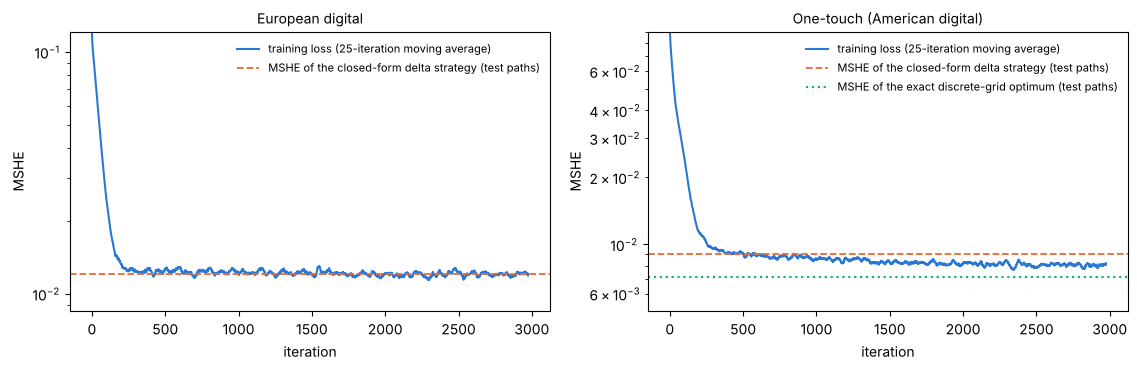

In [5]:
def hedging_error(payoff, w, theta, dS): return payoff - w - (theta*dS).sum(1)

def exact_strategy_along_paths(S, touched, nodes=401):
    '''exact discrete-grid optimum of the one-touch evaluated along paths (0 after the touch); coarser quadrature grid'''
    z = torch.linspace(-8.0, 8.0, nodes, **T64); w = phi(z)*(z[1] - z[0])
    out = torch.zeros(S.shape[0], N_STEPS, **T64)
    for k in range(N_STEPS):
        m = touched[:, k] < 0.5
        out[m, k] = discrete_optimum(k, S[m, k], 'touch', z=z, w=w)
    return out

# out-of-sample evaluation set: fresh paths, policies in eval mode; every strategy of a payoff uses the closed-form price as initial capital
with torch.no_grad():
    S, touched = simulate(N_TEST); dS = S[:, 1:] - S[:, :-1]
    pay = dict(digital=pay_digital(S, touched), touch=pay_touch(S, touched))
    theta = dict(digital={'cf': digital_cf(S[:, :-1], TAU)[1],
                          'learned': torch.stack([pol['digital'].hedge(k, S[:, k]) for k in range(N_STEPS)], 1)},
                 touch={'cf': one_touch_cf(S[:, :-1], TAU, touched[:, :-1])[1],
                        'exact': exact_strategy_along_paths(S, touched),
                        'learned': torch.stack([pol['touch'].hedge(k, S[:, k], touched[:, k]) for k in range(N_STEPS)], 1)})
    L = {kind: {s: hedging_error(pay[kind], PRICE[kind], th, dS) for s, th in theta[kind].items()} for kind in theta}
    mshe = {kind: {s: (e**2).mean().item() for s, e in L[kind].items()} for kind in L}
    rmse = {kind: {s: v**0.5 for s, v in mshe[kind].items()} for kind in mshe}

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
for a, kind, title in zip(ax, ('digital', 'touch'), ('European digital', 'One-touch (American digital)')):
    a.plot(np.convolve(hist[kind], np.ones(25)/25, mode='valid'), color=COL['learned'], lw=1.5, label='training loss (25-iteration moving average)')
    a.axhline(mshe[kind]['cf'], color=COL['cf'], ls='--', lw=1.3, label=f"MSHE of the {LABEL['cf']} strategy (test paths)")
    if 'exact' in mshe[kind]: a.axhline(mshe[kind]['exact'], color=COL['exact'], ls=':', lw=1.6, label='MSHE of the exact discrete-grid optimum (test paths)')
    a.set_yscale('log'); a.set_xlabel('iteration'); a.set_ylabel('MSHE'); a.set_title(title, fontsize=10); a.legend(frameon=False, fontsize=8)
    a.set_ylim(0.7*min(mshe[kind].values()), min(10*mshe[kind]['cf'], np.max(hist[kind])))
plt.tight_layout(); plt.show()

## 3. Learned controls vs. the closed forms

Out of sample: fresh test paths, policies in eval mode. All strategies of a given payoff use the closed-form price as initial
capital, so the hedging errors differ only through the hedge ratios. Hedge ratios are shown per basis point of the rate.

In [6]:
print(f"{'':14s}{'initial capital w':>22s}{'closed-form price':>20s}{'MC price':>12s}{'a_0 learned /bp':>18s}{'closed form /bp':>18s}")
for kind, name in (('digital', 'digital'), ('touch', 'one-touch')):
    cf0 = (digital_cf if kind == 'digital' else lambda s, t: one_touch_cf(s, t, zero0))(S0t, tau_k(0))[1].item()
    print(f"{name:14s}{pol[kind].w.item():22.4f}{PRICE[kind]:20.4f}{pay[kind].mean().item():12.4f}{pol[kind].hedge(0, S0t[None]).item()*BP:18.5f}{cf0*BP:18.5f}")
print()
print(f"{'RMSE of the terminal hedging error':38s}{'closed-form delta':>20s}{'exact discrete':>18s}{'learned':>12s}")
for kind, name in (('digital', 'European digital'), ('touch', 'one-touch')):
    print(f"{name:38s}{rmse[kind]['cf']:20.4f}{(f'{rmse[kind]['exact']:18.4f}' if 'exact' in rmse[kind] else f'{'= closed form':>18s}')}{rmse[kind]['learned']:12.4f}")
print(f'\n(all four strategies rebalance on the same N = {N_STEPS} grid; in continuous time every one of them replicates and the error is zero)')

                   initial capital w   closed-form price    MC price   a_0 learned /bp   closed form /bp
digital                       0.2267              0.2266      0.2255           0.00378           0.00376
one-touch                     0.4533              0.4533      0.4530           0.00754           0.00753

RMSE of the terminal hedging error       closed-form delta    exact discrete     learned
European digital                                    0.1100     = closed form      0.1101
one-touch                                           0.0949            0.0846      0.0911

(all four strategies rebalance on the same N = 100 grid; in continuous time every one of them replicates and the error is zero)


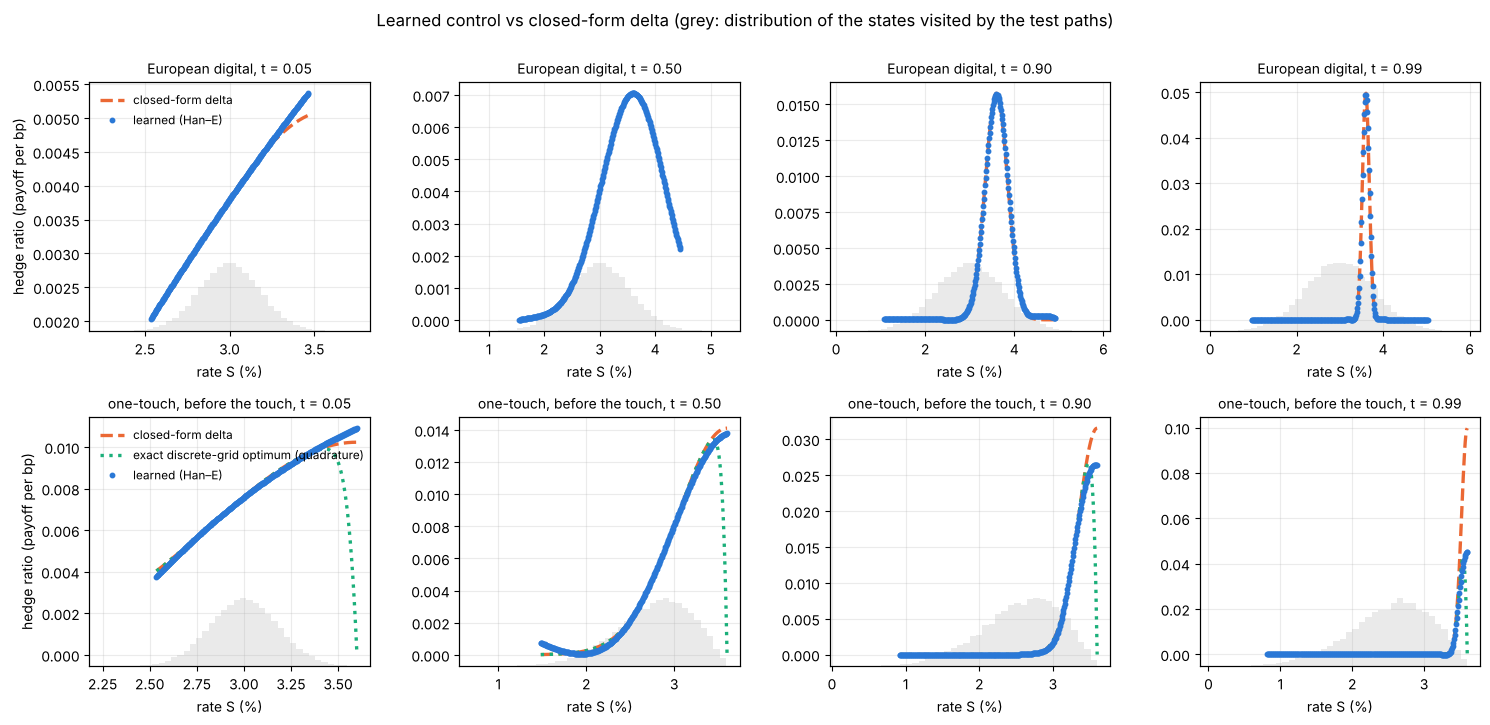

In [7]:
def visited(k, kind):
    s = S[:, k] if kind == 'digital' else S[touched[:, k] < 0.5, k]
    lo = torch.quantile(s, 0.005).item(); hi = torch.quantile(s, 0.995).item() if kind == 'digital' else K
    return s, torch.linspace(lo, hi, 300, **T64)

times = (5, 50, 90, 99)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2))
for r, (kind, name) in enumerate((('digital', 'European digital'), ('touch', 'one-touch, before the touch'))):
    for ax, k in zip(axes[r], times):
        s_vis, Sx = visited(k, kind); z = torch.zeros_like(Sx)
        with torch.no_grad():
            cf = (digital_cf(Sx, tau_k(k))[1] if kind == 'digital' else one_touch_cf(Sx, tau_k(k), z)[1])
            ex = discrete_optimum(k, Sx, kind)
            ln = pol[kind].hedge(k, Sx, z)
        ax.plot(Sx.cpu()*100, cf.cpu()*BP, '--', color=COL['cf'], lw=2.4, label=LABEL['cf'])
        if kind == 'touch': ax.plot(Sx.cpu()*100, ex.cpu()*BP, ':', color=COL['exact'], lw=2.4, label=LABEL['exact'])
        ax.plot(Sx.cpu()*100, ln.cpu()*BP, 'o', color=COL['learned'], ms=3.2, label=LABEL['learned'])
        ax2 = ax.twinx(); ax2.hist(s_vis.cpu().numpy()*100, bins=40, color='0.55', alpha=0.18); ax2.set_yticks([]); ax2.set_ylim(top=ax2.get_ylim()[1]*3.5)
        ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
        ax.set_title(f'{name}, t = {k*dt:.2f}', fontsize=10); ax.set_xlabel('rate S (%)'); ax.grid(alpha=0.25)
        if k == times[0]: ax.set_ylabel('hedge ratio (payoff per bp)')
axes[0, 0].legend(frameon=False, fontsize=8.5, loc='upper left'); axes[1, 0].legend(frameon=False, fontsize=8.5, loc='upper left')
fig.suptitle('Learned control vs closed-form delta (grey: distribution of the states visited by the test paths)', y=1.0)
plt.tight_layout(); plt.show()

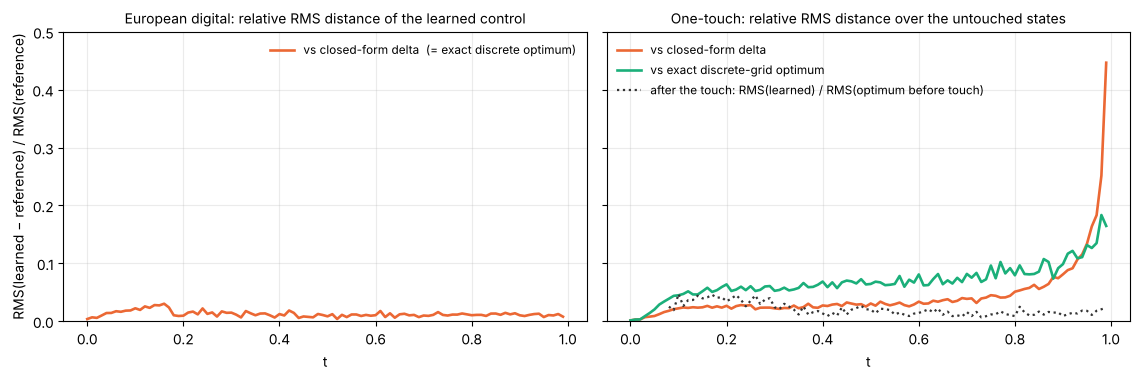

relative RMS distance, learned vs reference, averaged over t in [0, 0.5] / [0.5, 0.9] / [0.9, 1):
   digital  vs closed-form delta                          0.014 / 0.011 / 0.010
   touch    vs exact discrete-grid optimum (quadrature)   0.050 / 0.077 / 0.130
   touch    vs closed-form delta                          0.022 / 0.041 / 0.166
   one-touch after the touch: RMS(learned) / RMS(optimum before touch) = 0.021


In [8]:
def rel_rms(a, b, mask):
    num = ((a - b)**2*mask).sum(0)/mask.sum(0).clamp(min=1); den = (b**2*mask).sum(0)/mask.sum(0).clamp(min=1)
    return (num/den).sqrt().cpu().numpy()

t_grid = dt*np.arange(N_STEPS); ones = torch.ones_like(theta['digital']['cf']); untouched = (touched[:, :-1] < 0.5).double()
after_touch = ((theta['touch']['learned']**2*(1 - untouched)).sum(0)/(1 - untouched).sum(0).clamp(min=1)).sqrt()
after_touch[(1 - untouched).sum(0) < 200] = float('nan')                                       # too few touched paths to say anything
before_touch = ((theta['touch']['exact']**2*untouched).sum(0)/untouched.sum(0).clamp(min=1)).sqrt()

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
ax[0].plot(t_grid, rel_rms(theta['digital']['learned'], theta['digital']['cf'], ones), color=COL['cf'], lw=1.9, label='vs closed-form delta  (= exact discrete optimum)')
ax[0].set_title('European digital: relative RMS distance of the learned control', fontsize=10)
ax[1].plot(t_grid, rel_rms(theta['touch']['learned'], theta['touch']['cf'], untouched), color=COL['cf'], lw=1.9, label='vs closed-form delta')
ax[1].plot(t_grid, rel_rms(theta['touch']['learned'], theta['touch']['exact'], untouched), color=COL['exact'], lw=1.9, label='vs exact discrete-grid optimum')
ax[1].plot(t_grid, (after_touch/before_touch).cpu().numpy(), color=COL['ref'], ls=':', lw=1.6, label='after the touch: RMS(learned) / RMS(optimum before touch)')
ax[1].set_title('One-touch: relative RMS distance over the untouched states', fontsize=10)
for a in ax: a.set_xlabel('t'); a.set_ylim(0, 0.5); a.legend(frameon=False, fontsize=8.5); a.grid(alpha=0.25)
ax[0].set_ylabel('RMS(learned − reference) / RMS(reference)')
plt.tight_layout(); plt.show()
print('relative RMS distance, learned vs reference, averaged over t in [0, 0.5] / [0.5, 0.9] / [0.9, 1):')
for kind, refname in (('digital', 'cf'), ('touch', 'exact'), ('touch', 'cf')):
    r = rel_rms(theta[kind]['learned'], theta[kind][refname], ones if kind == 'digital' else untouched)
    print(f"   {kind:8s} vs {LABEL[refname]:42s} {r[:50].mean():.3f} / {r[50:90].mean():.3f} / {r[90:].mean():.3f}")
print(f'   one-touch after the touch: RMS(learned) / RMS(optimum before touch) = {torch.nanmean(after_touch/before_touch).item():.3f}')

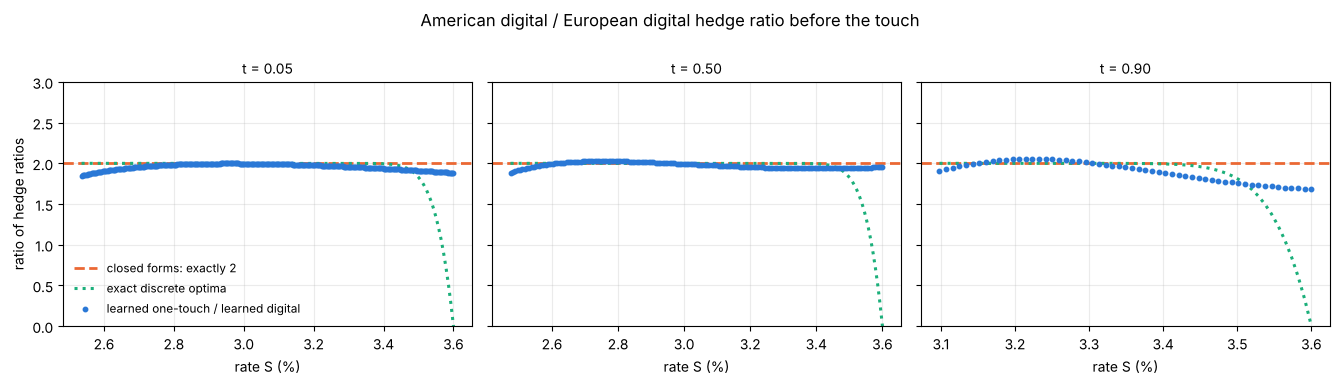

In [9]:
# reflection-principle check between the two *learned* policies: one-touch / digital = 2 before the touch (outside the barrier layer)
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.8), sharey=True)
for a, k in zip(ax, (5, 50, 90)):
    s_vis, Sx = visited(k, 'touch'); Sx = Sx[(Sx - K)/(SIGMA*math.sqrt(T - k*dt)) > -2.0]; z = torch.zeros_like(Sx)     # where both deltas are non-negligible
    with torch.no_grad():
        r_learned = pol['touch'].hedge(k, Sx, z)/pol['digital'].hedge(k, Sx)
        r_exact   = discrete_optimum(k, Sx, 'touch')/digital_cf(Sx, tau_k(k))[1]
    a.axhline(2.0, color=COL['cf'], ls='--', lw=2.0, label='closed forms: exactly 2')
    a.plot(Sx.cpu()*100, r_exact.cpu(), ':', color=COL['exact'], lw=2.2, label='exact discrete optima')
    a.plot(Sx.cpu()*100, r_learned.cpu(), 'o', color=COL['learned'], ms=3.2, label='learned one-touch / learned digital')
    a.set_title(f't = {k*dt:.2f}', fontsize=10); a.set_xlabel('rate S (%)'); a.set_ylim(0, 3); a.grid(alpha=0.25)
ax[0].set_ylabel('ratio of hedge ratios'); ax[0].legend(frameon=False, fontsize=8.5, loc='lower left')
fig.suptitle('American digital / European digital hedge ratio before the touch', y=1.0)
plt.tight_layout(); plt.show()

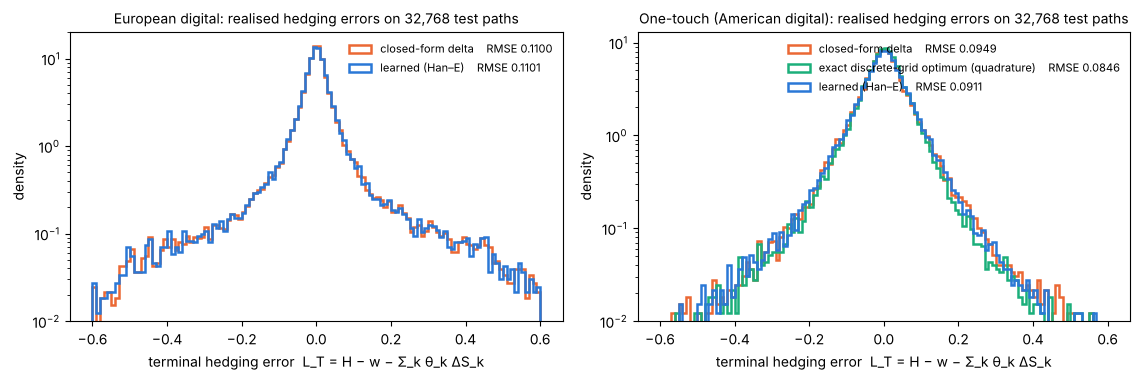

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
bins = np.linspace(-0.6, 0.6, 121)
for a, kind, name in zip(ax, ('digital', 'touch'), ('European digital', 'One-touch (American digital)')):
    for s in ('cf', 'exact', 'learned'):
        if s in L[kind]: a.hist(L[kind][s].cpu().numpy(), bins=bins, density=True, histtype='step', lw=1.8, color=COL[s], label=f"{LABEL[s]}    RMSE {rmse[kind][s]:.4f}")
    a.set_yscale('log'); a.set_ylim(bottom=1e-2); a.set_xlabel('terminal hedging error  L_T = H − w − Σ_k θ_k ΔS_k'); a.set_ylabel('density')
    a.set_title(f'{name}: realised hedging errors on {N_TEST:,} test paths', fontsize=10); a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Reading the results

* **European digital.** The learned control sits on the closed-form Bachelier delta at every time — relative RMS distance
  about 1% over the whole horizon — including the spike into expiry: the hedge at the last step is more than ten times the
  hedge at $t=0$ (0.05 vs 0.004 per bp at the peak) and the network found that scaling by itself (`TIME_SCALED_OUTPUT=False`).
  Because the discrete-grid optimum *is* the closed form here, that residual is pure optimisation/Monte-Carlo error, and the
  learned and closed-form strategies have the same hedging-error distribution — as they must in a complete market.
* **One-touch.** Over the states the paths visit, the learned control follows $2\phi(d)/(\sigma\sqrt\tau)$: the ratio of the two
  *learned* policies is 2 to within a few percent through the bulk of the state distribution (the ratio plot; it drifts
  towards 1.7 at $t=0.9$ as the barrier layer is approached), and after the touch the control is zero to about 2% of the
  pre-touch scale although nothing told it the claim was settled. The learned $a_0$ and
  $w$ reproduce the closed forms, $w$ to four digits. In the layer below the barrier the picture is the one Section 1 predicts:
  the closed form keeps growing towards $2\phi(0)/(\sigma\sqrt\tau)$, the exact discrete-grid optimum turns over and falls to
  zero, and the learned control sits between the two — it has learned to shrink the hedge where the closed form overshoots
  (its realised hedging error, 0.091, is below the closed-form delta's 0.095) but has not yet resolved the full dip (the exact
  optimum achieves 0.085). This is the data-limited corner of the problem: untouched paths are absorbed at $K$, so at $t=0.9$
  fewer than 0.3% of the paths sit within one step-standard-deviation of the barrier. The one-touch loss is still improving at
  the end of this run (see the training curve) and the GPU budget is set accordingly; the closed form, in contrast, is
  *wrong* in that layer for this problem and no amount of training should recover it there.

**What this does and does not show.** The Han–E stacked-policy approach recovers sharp, time-inhomogeneous and
path-dependent controls from the quadratic criterion alone, with closed-form targets to check against — and where the
closed form and the discrete problem disagree, the network follows the problem it was given, not the formula.
Hedging-error ranking is uninformative in a complete market by construction. Caveats: one strike/barrier, one grid; the
near-barrier fit is sample-limited; the exact discrete benchmark uses quadrature with a kinked integrand (accurate to about
$10^{-4}$ relative; the along-path version uses a coarser grid, about $10^{-3}$).

**Next for the talk.** The variance-optimal hedge of a digital is the textbook spike nobody trades. Add a transaction-cost or
position-limit penalty to the same cost functional and the learned policy should smooth into a call-spread-like overhedge —
a control problem with no closed form, solved with the same code.